# Wikispeedia EDA


In [1]:
import sys
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import PROCESSED_DIR, FIGURES_DIR
from src.data_loader import load_articles, load_links
from src.graph_utils import build_graph

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 4.5)


## 1. Загрузка данных


In [2]:
paths = pd.read_parquet(PROCESSED_DIR / "paths.parquet")
nodes = pd.read_parquet(PROCESSED_DIR / "node_features.parquet").set_index("article")
D = np.load(PROCESSED_DIR / "distance_matrix.npy")
tfidf_sim = np.load(PROCESSED_DIR / "tfidf_sim.npy")
with open(PROCESSED_DIR / "article_to_idx.json", encoding="utf-8") as f:
    article_to_idx = json.load(f)

articles_df = load_articles()
links_df = load_links()
G = build_graph(links_df, articles_df)

print(f"Партий: {len(paths):,} | Статей: {len(nodes):,} | Рёбер: {G.number_of_edges():,}")
print("Сплиты:\n", paths["split"].value_counts())


Партий: 76,193 | Статей: 4,604 | Рёбер: 119,882
Сплиты:
 split
train    56203
test     10269
val       9721
Name: count, dtype: int64


## 2. Распределение числа шагов и типы исходов


Finished hops:
 count    51318.000000
mean         5.757434
std          4.680718
min          0.000000
25%          4.000000
50%          5.000000
75%          7.000000
max        434.000000
Name: n_steps, dtype: float64

Unfinished types:
 type
restart    15552
timeout     9323
Name: count, dtype: int64


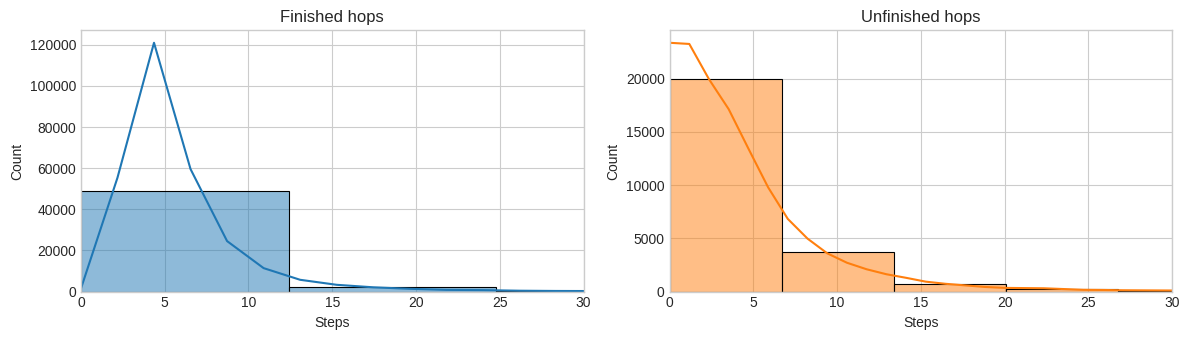

In [3]:
fin = paths[paths["finished"] == 1]
unf = paths[paths["finished"] == 0]

print("Finished hops:\n", fin["n_steps"].describe())
print("\nUnfinished types:\n", unf["type"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

sns.histplot(fin["n_steps"], bins=35, ax=axes[0], color="tab:blue", kde=True)
axes[0].set_title("Finished hops")
axes[0].set_xlabel("Steps")
axes[0].set_xlim(0, 30)

sns.histplot(unf["n_steps"], bins=35, ax=axes[1], color="tab:orange", kde=True)
axes[1].set_title("Unfinished hops")
axes[1].set_xlabel("Steps")
axes[1].set_xlim(0, 30)

plt.tight_layout()
plt.show()


## 3. Хабы и степени вершин графа


Топ-5 out-degree:
                                 out_degree  in_degree  pagerank
article                                                        
United_States                          294       1551  0.009562
Driving_on_the_left_or_right           255          0  0.000033
List_of_countries                      244         63  0.000364
List_of_circulating_currencies         236          8  0.000228
List_of_sovereign_states               216         43  0.000231

Топ-5 in-degree:
                 in_degree  out_degree  pagerank
article                                        
United_States        1551         294  0.009562
United_Kingdom        972         168  0.006232
France                959          85  0.006420
Europe                933         159  0.006337
World_War_II          751         119  0.004723

Топ-5 PageRank:
                   pagerank  in_degree  out_degree
article                                          
United_States     0.009562       1551         294
France    

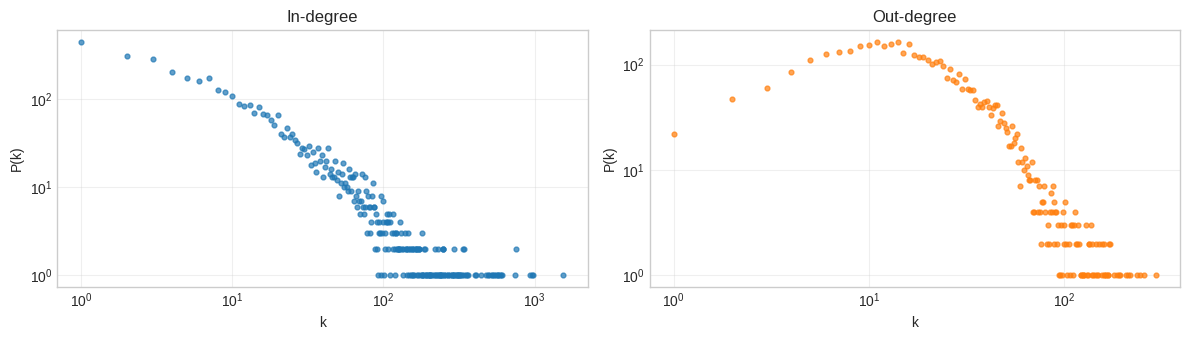

In [4]:
print("Топ-5 out-degree:\n", nodes.sort_values("out_degree", ascending=False)[["out_degree", "in_degree", "pagerank"]].head(5))
print("\nТоп-5 in-degree:\n", nodes.sort_values("in_degree", ascending=False)[["in_degree", "out_degree", "pagerank"]].head(5))
print("\nТоп-5 PageRank:\n", nodes.sort_values("pagerank", ascending=False)[["pagerank", "in_degree", "out_degree"]].head(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

for ax, col, title, color in [
    (axes[0], "in_degree", "In-degree", "tab:blue"),
    (axes[1], "out_degree", "Out-degree", "tab:orange"),
]:
    counts = Counter(nodes[col])
    xs = sorted(k for k in counts.keys() if k > 0)
    ys = [counts[x] for x in xs]
    ax.scatter(xs, ys, s=12, alpha=0.7, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("k")
    ax.set_ylabel("P(k)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Оверхед человека (actual / shortest)


           shortest        actual      overhead
count  51306.000000  51306.000000  51306.000000
mean       2.846100      5.758761      2.030605
std        0.699601      4.680459      1.721314
min        1.000000      1.000000      1.000000
25%        2.000000      4.000000      1.333333
50%        3.000000      5.000000      1.666667
75%        3.000000      7.000000      2.333333
max        6.000000    434.000000    217.000000
Медианный оверхед: 1.67


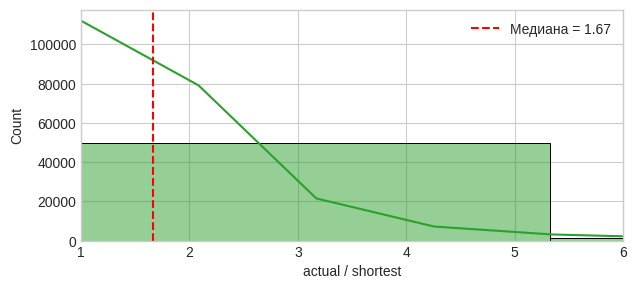

In [5]:
rows = []
for start, target, actual in zip(fin["start"], fin["target"], fin["n_steps"]):
    if start in article_to_idx and target in article_to_idx:
        sp = D[article_to_idx[start], article_to_idx[target]]
        if sp > 0:
            rows.append({
                "start": start,
                "target": target,
                "shortest": sp,
                "actual": actual,
                "overhead": actual / sp
            })

cmp_df = pd.DataFrame(rows)
print(cmp_df[["shortest", "actual", "overhead"]].describe())
print(f"Медианный оверхед: {cmp_df['overhead'].median():.2f}")

plt.figure(figsize=(7, 3))
sns.histplot(cmp_df["overhead"], bins=50, color="tab:green", kde=True)
plt.axvline(cmp_df["overhead"].median(), color="red", linestyle="--", label=f"Медиана = {cmp_df['overhead'].median():.2f}")
plt.xlabel("actual / shortest")
plt.xlim(1, 6)
plt.legend()
plt.show()


## 5. Динамика степени и расстояния до цели


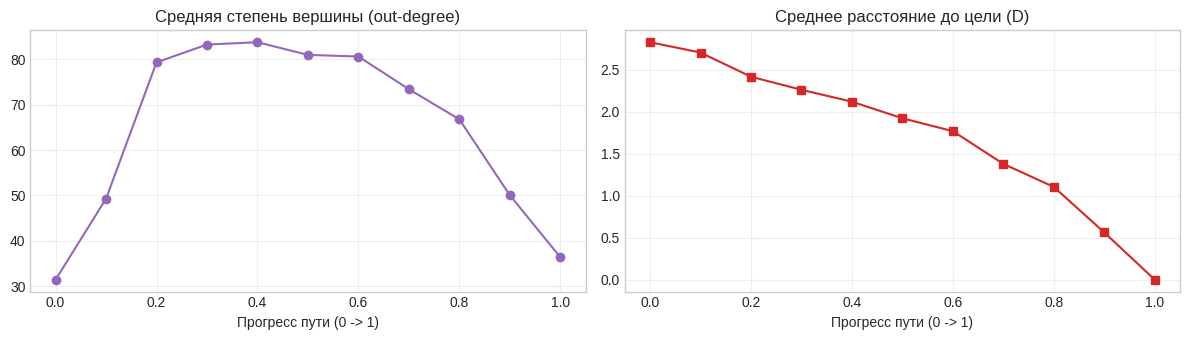

In [6]:
train_fin = fin[fin["split"] == "train"]

steps_norm = np.linspace(0, 1, 11)
avg_degrees = []
avg_dists = []

for s in steps_norm:
    degs_at_s = []
    dists_at_s = []
    for trace, target in zip(train_fin["trace"], train_fin["target"]):
        if len(trace) < 2 or target not in article_to_idx:
            continue
        idx_step = int(round(s * (len(trace) - 1)))
        node = trace[idx_step]
        if node in nodes.index:
            degs_at_s.append(nodes.loc[node, "out_degree"])
        if node in article_to_idx:
            d = D[article_to_idx[node], article_to_idx[target]]
            if d >= 0:
                dists_at_s.append(d)
    avg_degrees.append(np.mean(degs_at_s))
    avg_dists.append(np.mean(dists_at_s))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(steps_norm, avg_degrees, marker="o", color="tab:purple", linewidth=1.5)
axes[0].set_title("Средняя степень вершины (out-degree)")
axes[0].set_xlabel("Прогресс пути (0 -> 1)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(steps_norm, avg_dists, marker="s", color="tab:red", linewidth=1.5)
axes[1].set_title("Среднее расстояние до цели (D)")
axes[1].set_xlabel("Прогресс пути (0 -> 1)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Точки отказа (Drop-off rate)


                                                    drop_rate_train  \
article                                                               
Wikipedia_Text_of_the_GNU_Free_Documentation_Li...         0.505155   
Down_syndrome                                              0.444444   
Household_income_in_the_United_States                      0.400000   
United_States_Virgin_Islands                               0.363636   
Railway_post_office                                        0.363636   
Peace                                                      0.357143   
Looney_Tunes                                               0.333333   
Land_(economics)                                           0.333333   
Cardiff                                                    0.307692   
The_Fens                                                   0.300000   

                                                    in_degree  out_degree  
article                                                                

/tmp/ipykernel_38/235345974.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


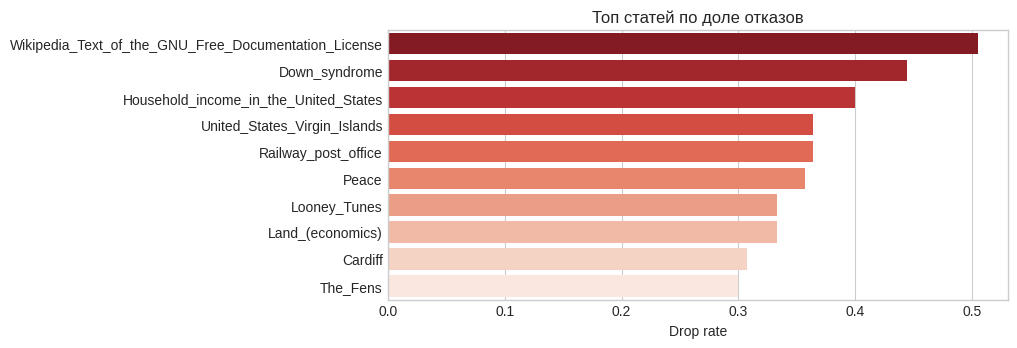

In [7]:
high_drop = nodes[nodes["drop_rate_train"] > 0].sort_values("drop_rate_train", ascending=False).head(10)
print(high_drop[["drop_rate_train", "in_degree", "out_degree"]])

plt.figure(figsize=(8, 3.5))
sns.barplot(
    x=high_drop["drop_rate_train"],
    y=high_drop.index,
    palette="Reds_r"
)
plt.xlabel("Drop rate")
plt.ylabel("")
plt.title("Топ статей по доле отказов")
plt.show()


## 7. Модель предсказания успеха на шаге k=5


ROC-AUC (Val, k=5):
  Logistic Regression: 0.7799
  HistGradientBoosting: 0.7793


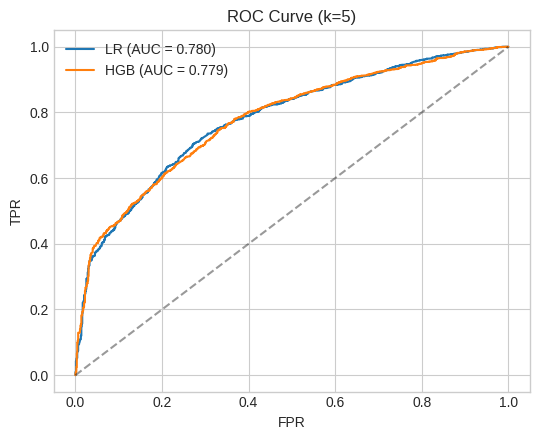

In [8]:
K = 5

def extract_features(trace, target, k=5):
    if len(trace) < k + 1 or target in trace[:k + 1]:
        return None
    
    prefix = trace[:k + 1]
    curr = prefix[-1]
    start = prefix[0]
    
    d_curr = D[article_to_idx[curr], article_to_idx[target]] if (curr in article_to_idx and target in article_to_idx) else 99
    d_start = D[article_to_idx[start], article_to_idx[target]] if (start in article_to_idx and target in article_to_idx) else 99
    
    if d_curr == -1: d_curr = 99
    if d_start == -1: d_start = 99
    
    all_dists = [
        D[article_to_idx[a], article_to_idx[target]]
        for a in prefix
        if a in article_to_idx and target in article_to_idx and D[article_to_idx[a], article_to_idx[target]] != -1
    ]
    d_min = min(all_dists) if all_dists else 99
    
    return {
        "dist_current": d_curr,
        "dist_min": d_min,
        "dist_delta": d_start - d_curr,
        "in_degree": nodes.loc[curr, "in_degree"] if curr in nodes.index else 0,
        "out_degree": nodes.loc[curr, "out_degree"] if curr in nodes.index else 0,
        "pagerank": nodes.loc[curr, "pagerank"] if curr in nodes.index else 0.0,
        "drop_rate": nodes.loc[curr, "drop_rate_train"] if curr in nodes.index else 0.0,
        "back_clicks": sum(1 for i in range(1, len(prefix)) if prefix[i] == prefix[i - 1]),
    }

train_data, val_data = [], []

for trace, target, finished, split in zip(paths["trace"], paths["target"], paths["finished"], paths["split"]):
    if split not in ("train", "val"):
        continue
    feats = extract_features(trace, target, k=K)
    if feats is not None:
        feats["label"] = finished
        if split == "train":
            train_data.append(feats)
        else:
            val_data.append(feats)

train_df = pd.DataFrame(train_data)
val_df = pd.DataFrame(val_data)

feature_cols = [c for c in train_df.columns if c != "label"]
X_train, y_train = train_df[feature_cols], train_df["label"]
X_val, y_val = val_df[feature_cols], val_df["label"]

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_tr_s, y_train)
y_pred_lr = lr.predict_proba(X_val_s)[:, 1]
auc_lr = roc_auc_score(y_val, y_pred_lr)

hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train, y_train)
y_pred_hgb = hgb.predict_proba(X_val)[:, 1]
auc_hgb = roc_auc_score(y_val, y_pred_hgb)

print(f"ROC-AUC (Val, k={K}):")
print(f"  Logistic Regression: {auc_lr:.4f}")
print(f"  HistGradientBoosting: {auc_hgb:.4f}")

plt.figure(figsize=(5.5, 4.5))
fpr_lr, tpr_lr, _ = roc_curve(y_val, y_pred_lr)
fpr_hgb, tpr_hgb, _ = roc_curve(y_val, y_pred_hgb)

plt.plot(fpr_lr, tpr_lr, label=f"LR (AUC = {auc_lr:.3f})")
plt.plot(fpr_hgb, tpr_hgb, label=f"HGB (AUC = {auc_hgb:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title(f"ROC Curve (k={K})")
plt.legend()
plt.tight_layout()
plt.show()
